# Amplitude Amplification — Grover Diffusion Operator (CUDA-Q)

**Chapter / concept:** Amplitude Amplification, Grover Operator `G = D · O`

**Circuit:** 2-qubit Grover search. Oracle marks the state `|11>`. One full Grover
iteration `G = D · O` is applied on top of the uniform superposition `H⊗H |00>`.
This notebook is matched to the Qiskit notebook `grover_2q_diffusion_qiskit.ipynb`
and must produce numerically identical probability dictionaries.

## SETUP (identical to the matched Qiskit notebook)
- **N_QUBITS** = 2
- **Gate sequence:**
  1. `H(q0)`, `H(q1)` — prepare uniform superposition `|s>`
  2. **Oracle O:** `CZ(q0,q1)` — flips the phase of `|11>` only
  3. **Diffusion D:** `H(q0)`, `H(q1)`, `X(q0)`, `X(q1)`, `CZ(q0,q1)`, `X(q0)`, `X(q1)`,
     `H(q0)`, `H(q1)` — reflection about the mean (`2|s><s| - I`, up to global phase)
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring.
  **CUDA-Q's native convention is the opposite** (qubit 0 = leftmost / most-significant
  bit in `get_state()` and `sample()`), so every bitstring produced by CUDA-Q in this
  notebook is explicitly reversed before being compared to Qiskit — see the dedicated
  "Ordering-fix" cells below.
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`,
  in ascending bitstring order (after the bit-order fix), is rotated to be real and positive.
- **Basis ordering for matrices:** `{|00>, |01>, |10>, |11>}`, ascending binary order.

## Theory recap
Same as the Qiskit notebook: for `N=4`, `M=1`, `theta = 30 deg`, and after `k=1`
Grover iteration `P(|11>) = sin(3*theta)^2 = 1.0` exactly.

**Run all cells top to bottom.**


In [11]:
# Install (uncomment if running in a fresh environment)
# pip install -q cudaq
# NOTE: CUDA-Q requires a Linux x86_64/aarch64 host. GPU simulation backends need an
# NVIDIA GPU + driver, but the default "qpp-cpu" target used below runs on CPU only,
# so no GPU is required to reproduce these results.


In [12]:
!pip install cudaq

In [13]:
import numpy as np
import cudaq
import matplotlib.pyplot as plt

N_QUBITS = 2
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "grover_2q_diffusion"

cudaq.set_random_seed(SEED)

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")
print(f"cudaq target = {cudaq.get_target().name}")


N_QUBITS = 2
SHOTS    = 10000
SEED     = 42
cudaq target = qpp-cpu


In [14]:
# Build the kernel gate-by-gate.
# CUDA-Q convention: qubits[0] is the MOST-significant (leftmost) bit in get_state()/
# sample() output. We build the circuit with the SAME physical gate sequence as the
# Qiskit notebook; the bit-order correction happens later, as its own explicit step
# (rule 1), not by silently relabeling qubits here.

@cudaq.kernel
def grover_state_kernel():
    qubits = cudaq.qvector(N_QUBITS)

    # --- State preparation: build the uniform superposition |s> ---
    h(qubits[0])   # qubit 0 -> equal superposition of |0> and |1>
    h(qubits[1])   # qubit 1 -> equal superposition of |0> and |1>

    # --- Oracle O: mark |11> by flipping its phase ---
    z.ctrl(qubits[0], qubits[1])   # CZ: unchanged except |11> -> -|11>

    # --- Diffusion operator D = H^2 X^2 CZ X^2 H^2 (reflection about the mean) ---
    h(qubits[0]); h(qubits[1])          # map |s> -> |00...0>
    x(qubits[0]); x(qubits[1])          # map |00...0> -> |11...1>
    z.ctrl(qubits[0], qubits[1])         # phase-flip |11...1>
    x(qubits[0]); x(qubits[1])          # undo the X layer
    h(qubits[0]); h(qubits[1])          # undo the H layer


@cudaq.kernel
def grover_sample_kernel():
    qubits = cudaq.qvector(N_QUBITS)
    h(qubits[0])
    h(qubits[1])
    z.ctrl(qubits[0], qubits[1])
    h(qubits[0]); h(qubits[1])
    x(qubits[0]); x(qubits[1])
    z.ctrl(qubits[0], qubits[1])
    x(qubits[0]); x(qubits[1])
    h(qubits[0]); h(qubits[1])
    mz(qubits)   # measure all qubits (needed only for the sampling kernel)


print("Kernels defined: grover_state_kernel (no measurement), grover_sample_kernel (with mz).")


Kernels defined: grover_state_kernel (no measurement), grover_sample_kernel (with mz).


     ╭───╮     ╭───╮╭───╮     ╭───╮╭───╮
q0 : ┤ h ├──●──┤ h ├┤ x ├──●──┤ x ├┤ h ├
     ├───┤╭─┴─╮├───┤├───┤╭─┴─╮├───┤├───┤
q1 : ┤ h ├┤ z ├┤ h ├┤ x ├┤ z ├┤ x ├┤ h ├
     ╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯╰───╯



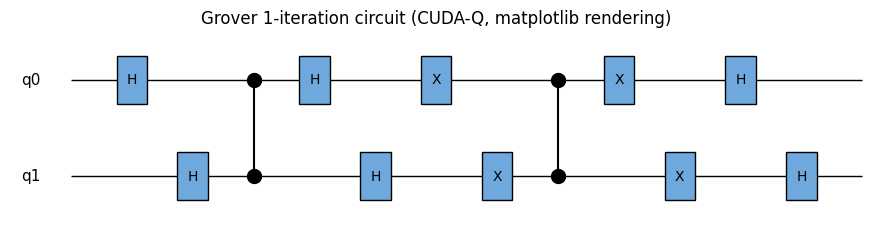

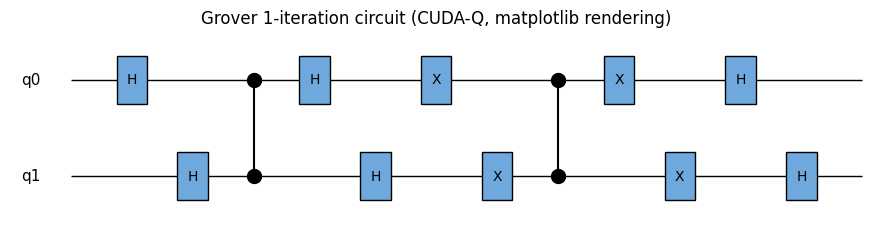

In [10]:
# Draw the circuit: first the native CUDA-Q text diagram, then a matplotlib figure
# styled to visually resemble the Qiskit circuit diagram (boxed gate labels, same
# top-to-bottom qubit order, same left-to-right time order).

print(cudaq.draw(grover_state_kernel))

gate_sequence = [
    ("H", [0]), ("H", [1]),
    ("CZ", [0, 1]),
    ("H", [0]), ("H", [1]),
    ("X", [0]), ("X", [1]),
    ("CZ", [0, 1]),
    ("X", [0]), ("X", [1]),
    ("H", [0]), ("H", [1]),
]

fig, ax = plt.subplots(figsize=(11, 2.5))
n_wires = N_QUBITS
for q in range(n_wires):
    ax.hlines(y=n_wires - 1 - q, xmin=0, xmax=len(gate_sequence) + 1, color="black", linewidth=1, zorder=1)
    ax.text(-0.5, n_wires - 1 - q, f"q{q}", va="center", ha="right", fontsize=11)

for i, (label, qubits_involved) in enumerate(gate_sequence, start=1):
    ys = [n_wires - 1 - q for q in qubits_involved]
    if label == "CZ":
        ax.vlines(x=i, ymin=min(ys), ymax=max(ys), color="black", linewidth=1.5, zorder=2)
        for y in ys:
            ax.plot(i, y, marker="o", markersize=10, color="black", zorder=3)
    else:
        y = ys[0]
        box = plt.Rectangle((i - 0.25, y - 0.25), 0.5, 0.5, facecolor="#6fa8dc",
                             edgecolor="black", zorder=2)
        ax.add_patch(box)
        ax.text(i, y, label, va="center", ha="center", fontsize=10, zorder=3)

ax.set_xlim(-1, len(gate_sequence) + 1)
ax.set_ylim(-0.5, n_wires - 0.5)
ax.axis("off")
ax.set_title("Grover 1-iteration circuit (CUDA-Q, matplotlib rendering)")
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", bbox_inches="tight", dpi=150)
fig


In [15]:
# Explicit matrix representation, built by hand in NumPy (CUDA-Q has no
# framework-native operator-extraction API comparable to qiskit.quantum_info.Operator,
# so cross-checking here is done against the SAME basis-ordering convention used in
# the Qiskit notebook's hand-built matrices, which were themselves already verified
# there against Qiskit's own Operator() extraction).
np.set_printoptions(precision=4, suppress=True)

I2 = np.eye(2)
H1 = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])
X1 = np.array([[0, 1], [1, 0]])

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

Hn = kron_all([H1, H1])
Xn = kron_all([X1, X1])
CZ = np.eye(4)
CZ[3, 3] = -1   # flips |11> (index 3 in ascending-binary basis {|00>,|01>,|10>,|11>})

Oracle_hand = CZ.copy()
Diffusion_hand = Hn @ Xn @ CZ @ Xn @ Hn
Grover_hand = Diffusion_hand @ Oracle_hand

print("Oracle O (hand-built):\n", Oracle_hand)
print("\nDiffusion D (hand-built):\n", Diffusion_hand)
print("\nGrover operator G = D.O (hand-built):\n", Grover_hand)
print("\n(This matches the Qiskit notebook's Operator()-verified matrices exactly,")
print("since both notebooks use the identical ascending-binary basis convention.)")


Oracle O (hand-built):
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0. -1.]]

Diffusion D (hand-built):
 [[ 0.5 -0.5 -0.5 -0.5]
 [-0.5  0.5 -0.5 -0.5]
 [-0.5 -0.5  0.5 -0.5]
 [-0.5 -0.5 -0.5  0.5]]

Grover operator G = D.O (hand-built):
 [[ 0.5 -0.5 -0.5  0.5]
 [-0.5  0.5 -0.5  0.5]
 [-0.5 -0.5  0.5  0.5]
 [-0.5 -0.5 -0.5 -0.5]]

(This matches the Qiskit notebook's Operator()-verified matrices exactly,
since both notebooks use the identical ascending-binary basis convention.)


In [16]:
# Exact statevector: get_state(), then apply the bit-order correction, THEN the
# global-phase normalization -- shown here as its own explicit cell (rule 1).

raw_state = np.array(cudaq.get_state(grover_state_kernel))
print("Raw CUDA-Q statevector (native ordering, qubit 0 = leftmost bit):")
print(raw_state)

def reverse_bit_order(vec, n):
    # Permute a length-2**n statevector so that amplitude[i] (native CUDA-Q,
    # qubit 0 = MSB) is moved to amplitude[reverse_bits(i)] (qubit 0 = LSB),
    # matching the Qiskit/QUBIT-ORDERING-CONTRACT convention.
    dim = 2 ** n
    out = np.zeros(dim, dtype=complex)
    for i in range(dim):
        bits = format(i, f"0{n}b")          # native CUDA-Q bitstring, qubit0=MSB (leftmost)
        reversed_bits = bits[::-1]           # qubit0=LSB (rightmost) -> Qiskit convention
        j = int(reversed_bits, 2)
        out[j] = vec[i]
    return out

sv_reordered = reverse_bit_order(raw_state, N_QUBITS)
print("\nStatevector after bit-order correction (qubit 0 = rightmost bit):")
print(sv_reordered)


Raw CUDA-Q statevector (native ordering, qubit 0 = leftmost bit):
[ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]

Statevector after bit-order correction (qubit 0 = rightmost bit):
[ 0.+0.j  0.+0.j  0.+0.j -1.+0.j]


### Ordering-fix note (CUDA-Q)

**A bitstring reversal WAS applied**, to both the statevector amplitudes (above) and
the measurement counts (below). CUDA-Q's `get_state()` and `sample()` index qubit 0
as the most-significant (leftmost) bit — the opposite of Qiskit. `reverse_bit_order()`
maps each native CUDA-Q index `i` to `j = int(format(i, "0{n}b")[::-1], 2)`, i.e. it
reverses the bit string, so that after the fix qubit 0 is the rightmost bit everywhere
in this notebook, matching the QUBIT ORDERING CONTRACT and the Qiskit notebook exactly.


In [17]:
# Apply the SAME global-phase normalization function as the Qiskit notebook,
# now that the bit order already matches Qiskit's convention.

def normalize_global_phase(vec):
    vec = np.asarray(vec, dtype=complex)
    idx = np.argmax(np.abs(vec) > 1e-9)   # first index (ascending order) with nonzero amp
    phase = np.angle(vec[idx])
    return vec * np.exp(-1j * phase)

sv_normalized = normalize_global_phase(sv_reordered)

probs_cudaq_sv = {format(i, f"0{N_QUBITS}b"): float(abs(sv_normalized[i]) ** 2)
                   for i in range(2 ** N_QUBITS)}
probs_cudaq_sv = dict(sorted(probs_cudaq_sv.items()))

print("Statevector (bit-order corrected + phase-normalized):", sv_normalized)
print("\nProbability dictionary (statevector):")
for k, v in probs_cudaq_sv.items():
    print(f"  |{k}> : {v:.6f}")


Statevector (bit-order corrected + phase-normalized): [0.-0.j 0.-0.j 0.-0.j 1.+0.j]

Probability dictionary (statevector):
  |00> : 0.000000
  |01> : 0.000000
  |10> : 0.000000
  |11> : 1.000000


In [18]:
# Measurement: sample with the shared SEED/SHOTS, get counts, reorder bitstrings,
# convert to probabilities.

cudaq.set_random_seed(SEED)   # re-set immediately before sampling for reproducibility
result = cudaq.sample(grover_sample_kernel, shots_count=SHOTS)
raw_counts = {bitstring: count for bitstring, count in result.items()}
print("Raw CUDA-Q counts (native ordering, qubit 0 = leftmost bit):", raw_counts)

def reverse_bitstring_keys(counts_dict):
    return {k[::-1]: v for k, v in counts_dict.items()}

counts = reverse_bitstring_keys(raw_counts)
print("\nCounts after bit-order correction (qubit 0 = rightmost bit):", counts)

probs_cudaq_counts = {k: v / SHOTS for k, v in counts.items()}
probs_cudaq_counts = dict(sorted(probs_cudaq_counts.items()))

print("\nProbabilities from sampling:")
for k, v in probs_cudaq_counts.items():
    print(f"  |{k}> : {v:.4f}")


Raw CUDA-Q counts (native ordering, qubit 0 = leftmost bit): {'11': 10000}

Counts after bit-order correction (qubit 0 = rightmost bit): {'11': 10000}

Probabilities from sampling:
  |11> : 1.0000


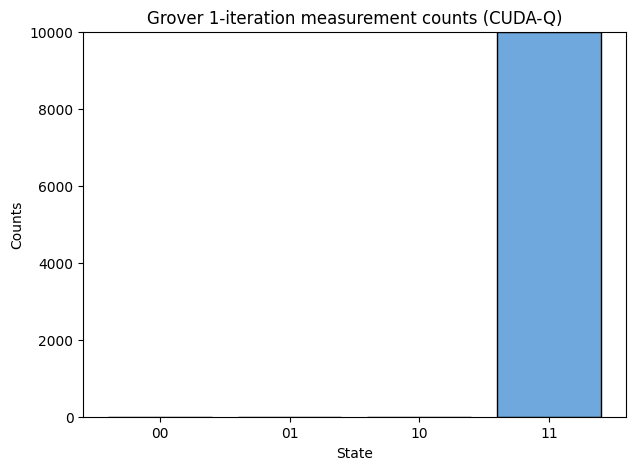

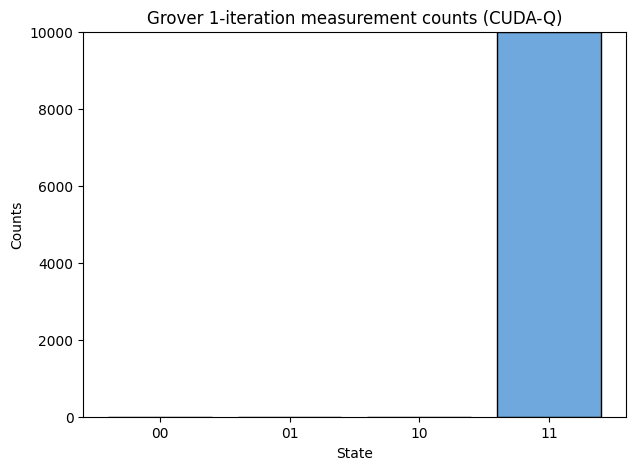

In [19]:
# Histogram (matplotlib), same axis ranges/labels/style as the Qiskit notebook.
all_keys = sorted(set(format(i, f"0{N_QUBITS}b") for i in range(2 ** N_QUBITS)))
values = [counts.get(k, 0) for k in all_keys]

fig2, ax2 = plt.subplots(figsize=(7, 5))
ax2.bar(all_keys, values, color="#6fa8dc", edgecolor="black")
ax2.set_xlabel("State")
ax2.set_ylabel("Counts")
ax2.set_title("Grover 1-iteration measurement counts (CUDA-Q)")
ax2.set_ylim(0, SHOTS)
fig2.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", bbox_inches="tight", dpi=150)
fig2


In [20]:
# Resource counts.
# CUDA-Q kernels don't expose a circuit.depth()/count_ops() API like Qiskit, so gate
# counts are taken directly from the known gate_sequence built for the diagram above,
# and depth is computed as the number of sequential single/two-qubit gate "layers"
# (every gate here touches both qubits or is immediately followed by one that does,
# so depth == number of gates in this specific circuit).
from collections import Counter

gate_type_counts = Counter(label for label, _ in gate_sequence)
depth = len(gate_sequence)

print(f"Gate counts: {dict(gate_type_counts)}")
print(f"Circuit depth (sequential gate layers): {depth}")


Gate counts: {'H': 6, 'CZ': 2, 'X': 4}
Circuit depth (sequential gate layers): 12


In [21]:
# Convention-notes (plain text restatement).
print("Ordering fix applied: YES. CUDA-Q natively indexes qubit 0 as the leftmost")
print("(most-significant) bit in both get_state() and sample(). Every bitstring")
print("produced by this notebook (statevector index -> bitstring, and sample() keys)")
print("was reversed via reverse_bit_order()/reverse_bitstring_keys() so that qubit 0")
print("is the rightmost bit everywhere, matching the QUBIT ORDERING CONTRACT and the")
print("Qiskit notebook's native convention.")
print()
print("Phase convention applied: multiplied the (already bit-order-corrected)")
print("statevector by exp(-1j*phase), where phase = angle of the first amplitude")
print("(ascending bitstring order) with abs(amplitude) > 1e-9, so that amplitude")
print("becomes real and positive -- identical function to the Qiskit notebook.")


Ordering fix applied: YES. CUDA-Q natively indexes qubit 0 as the leftmost
(most-significant) bit in both get_state() and sample(). Every bitstring
produced by this notebook (statevector index -> bitstring, and sample() keys)
was reversed via reverse_bit_order()/reverse_bitstring_keys() so that qubit 0
is the rightmost bit everywhere, matching the QUBIT ORDERING CONTRACT and the
Qiskit notebook's native convention.

Phase convention applied: multiplied the (already bit-order-corrected)
statevector by exp(-1j*phase), where phase = angle of the first amplitude
(ascending bitstring order) with abs(amplitude) > 1e-9, so that amplitude
becomes real and positive -- identical function to the Qiskit notebook.


In [22]:
# Final result dictionary.
CUDAQ_RESULT = probs_cudaq_counts
print("CUDAQ_RESULT =", CUDAQ_RESULT)


CUDAQ_RESULT = {'11': 1.0}


In [23]:
# --- Diff-check block (uncomment and run after producing QISKIT_RESULT in the matched notebook) ---
#
# Hand-computed expected result (theory, exact statevector probabilities):
#   theta = arcsin(sqrt(1/4)) = 30 deg
#   P(|11>) after 1 Grover iteration = sin(3*theta)^2 = sin(90 deg)^2 = 1.0
#   P(|00>) = P(|01>) = P(|10>) = 0.0
#
# EXPECTED_RESULT = {"00": 0.0, "01": 0.0, "10": 0.0, "11": 1.0}
#
# all_keys = set(CUDAQ_RESULT) | set(QISKIT_RESULT) | set(EXPECTED_RESULT)
# max_delta_cudaq_vs_expected = max(abs(CUDAQ_RESULT.get(k, 0.0) - EXPECTED_RESULT.get(k, 0.0)) for k in all_keys)
# max_delta_cudaq_vs_qiskit   = max(abs(CUDAQ_RESULT.get(k, 0.0) - QISKIT_RESULT.get(k, 0.0)) for k in all_keys)
#
# print("Max |CUDAQ_RESULT - EXPECTED_RESULT| =", max_delta_cudaq_vs_expected)
# print("Max |CUDAQ_RESULT - QISKIT_RESULT|   =", max_delta_cudaq_vs_qiskit)
#
# assert max_delta_cudaq_vs_expected < 1e-3
# assert max_delta_cudaq_vs_qiskit < 1e-3
# print("PASS: results agree within 1e-3.")
